# Predicting 30-day readmission in diabetic patients

Cleaning, features, model comparison, evaluation, explainability and a fairness check.
Exploration is in `01_eda.ipynb`.

101,766 stays from 130 US hospitals, 1999-2008, all diabetic. One row is one stay, not one
patient. Runs top to bottom in about two minutes.

## Setup

In [1]:
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (7, 4)

DATA = "../data/diabetic_data.csv"
IDS = "../data/IDS_mapping.csv"

## 1. Load

`?` is the missing-value marker in this file. Left alone, pandas reads it as a normal string
and `.isna()` returns nothing.

In [2]:
df = pd.read_csv(DATA, low_memory=False, na_values=["?"])

df.shape

(101766, 50)

In [3]:
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


## 2. Decoding the ID columns

`discharge_disposition_id` is stored as a number but it is a category. The dataset ships a
mapping file for it.

In [4]:
# the file holds three small tables stacked together, separated by blank rows.
# keep_default_na=False so the literal word "NULL" doesn't become NaN.
ids = pd.read_csv(IDS, header=None, names=["id", "description"], keep_default_na=False)

mappings = {}
current = None
for _, row in ids.iterrows():
    if row["id"] == "":
        continue
    if str(row["id"]).endswith("_id"):
        current = row["id"]
        mappings[current] = {}
    else:
        mappings[current][int(row["id"])] = row["description"]

discharge = mappings["discharge_disposition_id"]

counts = df["discharge_disposition_id"].value_counts().head(8)
for code, n in counts.items():
    print(code, n, discharge[code])

1 60234 Discharged to home
3 13954 Discharged/transferred to SNF
6 12902 Discharged/transferred to home with home health service
18 3691 NULL
2 2128 Discharged/transferred to another short term hospital
22 1993 Discharged/transferred to another rehab fac including rehab units of a hospital .
11 1642 Expired
5 1184 Discharged/transferred to another type of inpatient care institution


## 3. Removing patients who cannot be readmitted

Some discharge codes mean the patient died or went to hospice. Those patients cannot come
back, so they are guaranteed negatives that any model can spot from the discharge code
alone.

In [5]:
cannot_return = [11, 13, 14, 19, 20, 21]   # expired and hospice

target = (df["readmitted"] == "<30").astype(int)
for code in cannot_return:
    rows = df["discharge_disposition_id"] == code
    if rows.sum() > 0:
        print(code, rows.sum(), round(target[rows].mean(), 3), discharge[code])

removed = df["discharge_disposition_id"].isin(cannot_return)
print()
print("removing", removed.sum(), "rows")

df = df[~removed].reset_index(drop=True)
print("rows left:", len(df))

11 1642 0.0 Expired
13 399 0.048 Hospice / home
14 372 0.065 Hospice / medical facility
19 8 0.0 Expired at home. Medicaid only, hospice.
20 2 0.0 Expired in a medical facility. Medicaid only, hospice.

removing 2423 rows
rows left: 99343


Dropping them costs about 0.006 of AUC. The higher score was partly the model
recognising death certificates, so the lower number is the real one.

## 4. Target

Three values collapse to one binary flag. Merging `>30` with `NO` loses information, but the
30-day window is what hospitals are measured on.

In [6]:
y = (df["readmitted"] == "<30").astype(int)

print(df["readmitted"].value_counts())
print()
print("positive rate: %.2f%%" % (y.mean() * 100))
print("always predicting 0 would be %.1f%% accurate" % ((1 - y.mean()) * 100))

readmitted
NO     52527
>30    35502
<30    11314
Name: count, dtype: int64

positive rate: 11.39%
always predicting 0 would be 88.6% accurate


## 5. Repeat patients

Fewer patients than rows, so a random split would put the same person in train and test.

In [7]:
print("rows:    ", len(df))
print("patients:", df["patient_nbr"].nunique())
print("most stays by one patient:", df["patient_nbr"].value_counts().max())

rows:     99343
patients: 69990
most stays by one patient: 40


## 6. Features

Group the diagnosis codes, drop what is unusable, collapse rare levels, one-hot encode.
`patient_nbr` is kept aside for the split but never given to the model. `age` goes in as the
midpoint of each band since the bands are ordered.

`dummy_na=True` creates `A1Cresult_nan` and `max_glu_serum_nan`. A missing lab result here
means the test was never ordered rather than lost.

In [8]:
def group_diagnosis(code):
    if pd.isna(code):
        return "missing"
    code = str(code)
    if code.startswith(("E", "V")):
        return "other"
    try:
        n = float(code)
    except ValueError:
        return "other"

    if 390 <= n <= 459 or n == 785:
        return "circulatory"
    if 460 <= n <= 519 or n == 786:
        return "respiratory"
    if 520 <= n <= 579 or n == 787:
        return "digestive"
    if int(n) == 250:
        return "diabetes"
    if 800 <= n <= 999:
        return "injury"
    if 710 <= n <= 739:
        return "musculoskeletal"
    if 580 <= n <= 629 or n == 788:
        return "genitourinary"
    if 140 <= n <= 239:
        return "neoplasms"
    return "other"

print(df["diag_1"].nunique(), "codes in diag_1 ->",
      df["diag_1"].map(group_diagnosis).nunique(), "groups")

715 codes in diag_1 -> 10 groups


In [9]:
age_midpoint = {"[0-10)": 5, "[10-20)": 15, "[20-30)": 25, "[30-40)": 35,
                "[40-50)": 45, "[50-60)": 55, "[60-70)": 65, "[70-80)": 75,
                "[80-90)": 85, "[90-100)": 95}

data = df.copy()
for col in ["diag_1", "diag_2", "diag_3"]:
    data[col + "_group"] = data[col].map(group_diagnosis)
data["age"] = data["age"].map(age_midpoint)

patient_ids = data["patient_nbr"].copy()

data = data.drop(columns=[
    "encounter_id", "patient_nbr",                  # identifiers
    "weight", "payer_code", "medical_specialty",    # too incomplete
    "examide", "citoglipton",                       # one value only
    "diag_1", "diag_2", "diag_3",                   # replaced by the groups
    "readmitted",
])

# fold rare levels together so one-hot doesn't create near-empty columns
for col in data.select_dtypes("object").columns:
    freq = data[col].value_counts(normalize=True)
    rare = freq[freq < 0.01].index
    if len(rare) > 0:
        data[col] = data[col].where(~data[col].isin(rare), "rare")

X = pd.get_dummies(data, drop_first=True, dummy_na=True)
X.columns = [c.replace("[", "(").replace("]", ")") for c in X.columns]  # xgboost rejects brackets

print(df.shape[1], "raw columns ->", X.shape[1], "features")
X.head()

50 raw columns -> 112 features


,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,...,diag_3_group_diabetes,diag_3_group_digestive,diag_3_group_genitourinary,diag_3_group_injury,diag_3_group_missing,diag_3_group_musculoskeletal,diag_3_group_neoplasms,diag_3_group_other,diag_3_group_respiratory,diag_3_group_nan
0,5,6,25,1,1,41,0,1,0,0,...,False,False,False,False,True,False,False,False,False,False
1,15,1,1,7,3,59,0,18,0,0,...,False,False,False,False,False,False,False,True,False,False
2,25,1,1,7,2,11,5,13,2,0,...,False,False,False,False,False,False,False,True,False,False
3,35,1,1,7,2,44,1,16,0,0,...,False,False,False,False,False,False,False,False,False,False
4,45,1,1,7,1,51,0,8,0,0,...,True,False,False,False,False,False,False,False,False,False


## 7. Splitting by patient

`GroupShuffleSplit` on `patient_nbr` keeps all of one person's stays on the same side. The
overlap below has to be zero.

In [10]:
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.metrics import roc_auc_score

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_rows, test_rows = next(splitter.split(X, y, patient_ids))

X_train, X_test = X.iloc[train_rows], X.iloc[test_rows]
y_train, y_test = y.iloc[train_rows], y.iloc[test_rows]

train_patients = set(patient_ids.iloc[train_rows])
test_patients = set(patient_ids.iloc[test_rows])

print("train:", len(X_train), "rows,", len(train_patients), "patients")
print("test: ", len(X_test), "rows,", len(test_patients), "patients")
print("patients on both sides:", len(train_patients & test_patients))

train: 79541 rows, 55992 patients
test:  19802 rows, 13998 patients
patients on both sides: 0


### How much does the split matter?

Same model twice, only the split changes.

In [11]:
from xgboost import XGBClassifier

def small_model(X_fit, y_fit):
    weight = (y_fit == 0).sum() / (y_fit == 1).sum()
    model = XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.1,
                          scale_pos_weight=weight, eval_metric="auc",
                          n_jobs=-1, random_state=42)
    model.fit(X_fit, y_fit)
    return model

X_tr_r, X_te_r, y_tr_r, y_te_r = train_test_split(X, y, test_size=0.2,
                                                  random_state=42, stratify=y)
auc_random = roc_auc_score(y_te_r, small_model(X_tr_r, y_tr_r).predict_proba(X_te_r)[:, 1])
auc_patient = roc_auc_score(y_test, small_model(X_train, y_train).predict_proba(X_test)[:, 1])

shared = len(set(patient_ids.iloc[X_tr_r.index]) & set(patient_ids.iloc[X_te_r.index]))

print("random row split: %.4f" % auc_random)
print("patient split:    %.4f" % auc_patient)
print("difference:       %+.4f" % (auc_random - auc_patient))
print("patients in both halves of the random split:", shared)

random row split: 0.6720
patient split:    0.6655
difference:       +0.0066
patients in both halves of the random split: 6798


Small in absolute terms, but compare it to how much XGBoost beats logistic regression
in section 9. Splitting carelessly hands you a chunk of that for free and nothing looks
wrong from the outside.

## 8. Training

Logistic regression as the baseline, XGBoost as the comparison. Both handle the 11%
positive rate by re-weighting rather than resampling.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

start = time.time()
logreg = Pipeline([
    ("scale", StandardScaler(with_mean=False)),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
logreg.fit(X_train, y_train)
print("logistic regression: %.0fs" % (time.time() - start))

start = time.time()
xgb = XGBClassifier(
    n_estimators=300, max_depth=5, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    eval_metric="auc", n_jobs=-1, random_state=42,
)
xgb.fit(X_train, y_train)
print("xgboost: %.0fs" % (time.time() - start))

pred_logreg = logreg.predict_proba(X_test)[:, 1]
pred_xgb = xgb.predict_proba(X_test)[:, 1]

logistic regression: 0s


xgboost: 1s


### Why these two

Six algorithms on the same split and features, to check the choice rather than assume it.

In [13]:
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier)
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

others = {
    "random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                                            class_weight="balanced", n_jobs=-1, random_state=42),
    "extra trees": ExtraTreesClassifier(n_estimators=300, min_samples_leaf=20,
                                        class_weight="balanced", n_jobs=-1, random_state=42),
    "hist gradient boosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                                            class_weight="balanced", random_state=42),
    "decision tree (depth 5)": DecisionTreeClassifier(max_depth=5, class_weight="balanced",
                                                      random_state=42),
    "gaussian naive bayes": GaussianNB(),
}

scores = {"logistic regression": roc_auc_score(y_test, pred_logreg),
          "xgboost": roc_auc_score(y_test, pred_xgb)}

for name, model in others.items():
    model.fit(X_train, y_train)
    scores[name] = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])

pd.Series(scores, name="auc").sort_values(ascending=False).round(4)

xgboost                    0.6673
hist gradient boosting     0.6659
random forest              0.6625
extra trees                0.6532
decision tree (depth 5)    0.6507
logistic regression        0.6506
gaussian naive bayes       0.6099
Name: auc, dtype: float64

Every tree ensemble lands within 0.005 of the others, and the whole spread is 0.017 - about
the same as the leakage correction in section 7. The ceiling here is the data, not the
algorithm.

These are near-default settings, not tuned. A tuned forest would likely close the gap
further, which is the same conclusion.

## 9. Results

Look at the accuracy column last. Both models score below "always predict 0" while being
more useful than it, which is why accuracy is not the headline.

In [14]:
from sklearn.metrics import (roc_curve, precision_recall_curve, average_precision_score,
                             classification_report, confusion_matrix, brier_score_loss)

def top_decile_lift(truth, scores):
    top = np.argsort(scores)[::-1][:int(0.1 * len(truth))]
    return truth.iloc[top].mean() / truth.mean()

results = pd.DataFrame({
    "auc": [roc_auc_score(y_test, pred_logreg), roc_auc_score(y_test, pred_xgb)],
    "avg_precision": [average_precision_score(y_test, pred_logreg),
                      average_precision_score(y_test, pred_xgb)],
    "top_decile_lift": [top_decile_lift(y_test, pred_logreg), top_decile_lift(y_test, pred_xgb)],
    "accuracy_at_0.5": [((pred_logreg >= 0.5) == y_test).mean(),
                        ((pred_xgb >= 0.5) == y_test).mean()],
}, index=["logistic regression", "xgboost"]).round(4)

print(results)
print()
print("always predicting 0: %.3f accuracy" % (1 - y_test.mean()))

                        auc  avg_precision  top_decile_lift  accuracy_at_0.5
logistic regression  0.6506         0.2051           2.2385           0.6647
xgboost              0.6673         0.2245           2.4100           0.6619

always predicting 0: 0.888 accuracy


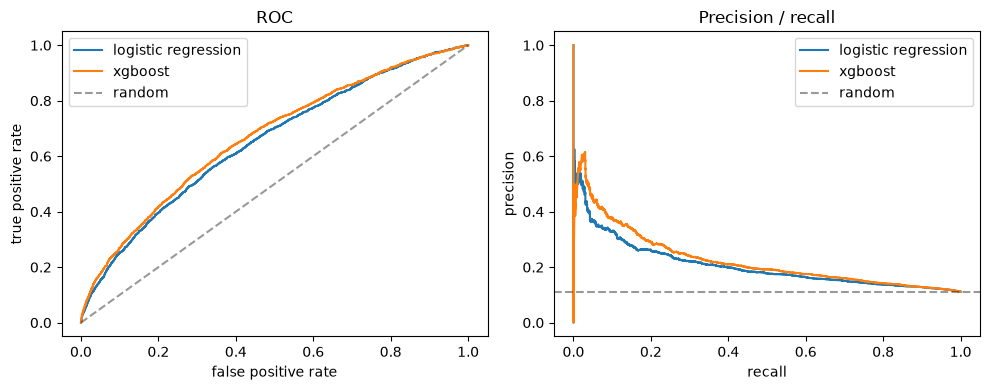

In [15]:
fpr_lr, tpr_lr, _ = roc_curve(y_test, pred_logreg)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, pred_xgb)
prec_lr, rec_lr, _ = precision_recall_curve(y_test, pred_logreg)
prec_xgb, rec_xgb, _ = precision_recall_curve(y_test, pred_xgb)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(fpr_lr, tpr_lr, label="logistic regression")
plt.plot(fpr_xgb, tpr_xgb, label="xgboost")
plt.plot([0, 1], [0, 1], "k--", alpha=0.4, label="random")
plt.xlabel("false positive rate")
plt.ylabel("true positive rate")
plt.title("ROC")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(rec_lr, prec_lr, label="logistic regression")
plt.plot(rec_xgb, prec_xgb, label="xgboost")
plt.axhline(y_test.mean(), color="k", linestyle="--", alpha=0.4, label="random")
plt.xlabel("recall")
plt.ylabel("precision")
plt.title("Precision / recall")
plt.legend()

plt.tight_layout()
plt.show()

Precision-recall is the more useful of the two, since ROC gets credit for the large pile of
true negatives an 11% positive rate guarantees. Around 0.67 is where this dataset tops out.

### Against the obvious rule

`number_inpatient` separates readmitted patients reasonably well on its own. Any hospital
could rank by that without a model, so it is the bar worth clearing.

In [16]:
prior_admissions = df["number_inpatient"].iloc[X_test.index].values

auc_model = roc_auc_score(y_test, pred_xgb)
auc_simple = roc_auc_score(y_test, prior_admissions)

ranked = np.argsort(prior_admissions, kind="stable")[::-1]
lift_simple = y_test.iloc[ranked[:int(0.1 * len(y_test))]].mean() / y_test.mean()

print("xgboost, %d features:   auc %.4f   lift %.2f" % (X.shape[1], auc_model, top_decile_lift(y_test, pred_xgb)))
print("number_inpatient alone: auc %.4f   lift %.2f" % (auc_simple, lift_simple))
print("difference:             %+.4f" % (auc_model - auc_simple))

xgboost, 112 features:   auc 0.6673   lift 2.41
number_inpatient alone: auc 0.6022   lift 2.03
difference:             +0.0651


The model wins by about 0.065 of AUC. That is real but smaller than the feature count
suggests, and it is the honest way to describe the contribution: most of what the model
knows is that frequent patients return, which the discharge team already knows.

### At a 0.5 threshold

In [17]:
cm = confusion_matrix(y_test, (pred_xgb >= 0.5).astype(int))
print(cm)
print()
print(classification_report(y_test, (pred_xgb >= 0.5).astype(int),
                            target_names=["not <30", "<30"], digits=3))

[[11846  5740]
 [  955  1261]]

              precision    recall  f1-score   support

     not <30      0.925     0.674     0.780     17586
         <30      0.180     0.569     0.274      2216

    accuracy                          0.662     19802
   macro avg      0.553     0.621     0.527     19802
weighted avg      0.842     0.662     0.723     19802



### Choosing a threshold

0.5 is a default, not a decision. The real constraint is how many patients the team can
call.

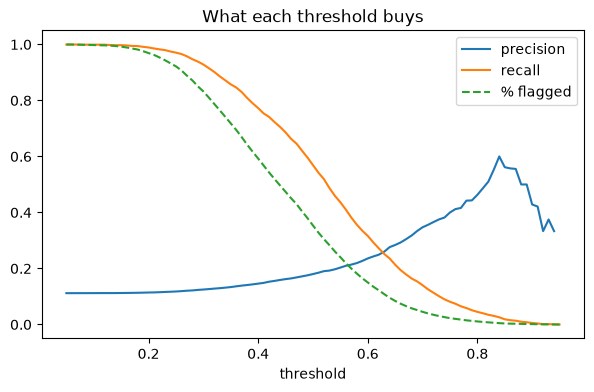

at 0.5: flags 35% of patients, catches 57% of readmissions, 18% precision


In [18]:
thresholds = np.arange(0.05, 0.96, 0.01)
precision, recall, flagged = [], [], []

for t in thresholds:
    flag = pred_xgb >= t
    caught = (flag & (y_test == 1)).sum()
    precision.append(caught / flag.sum())
    recall.append(caught / (y_test == 1).sum())
    flagged.append(flag.mean())

plt.plot(thresholds, precision, label="precision")
plt.plot(thresholds, recall, label="recall")
plt.plot(thresholds, flagged, "--", label="% flagged")
plt.xlabel("threshold")
plt.title("What each threshold buys")
plt.legend()
plt.show()

i = int(np.argmin(np.abs(thresholds - 0.5)))
print("at 0.5: flags %.0f%% of patients, catches %.0f%% of readmissions, %.0f%% precision"
      % (flagged[i] * 100, recall[i] * 100, precision[i] * 100))

### Cumulative gains

Sort patients by risk and walk down the list.

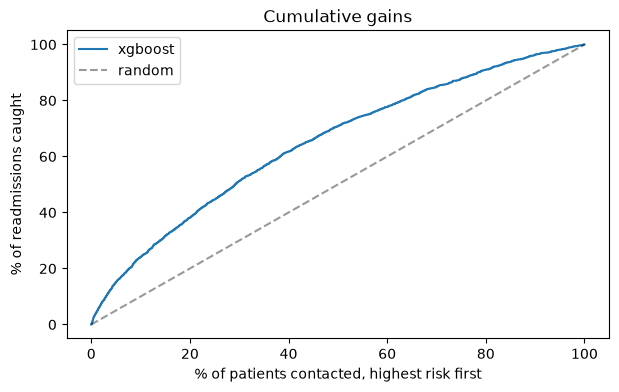

top 10% of risk holds 24% of readmissions (2.4x random)


In [19]:
order = np.argsort(pred_xgb)[::-1]
gains = np.cumsum(y_test.iloc[order].values) / y_test.sum() * 100
contacted = np.arange(1, len(gains) + 1) / len(gains) * 100

plt.plot(contacted, gains, label="xgboost")
plt.plot([0, 100], [0, 100], "k--", alpha=0.4, label="random")
plt.xlabel("% of patients contacted, highest risk first")
plt.ylabel("% of readmissions caught")
plt.title("Cumulative gains")
plt.legend()
plt.show()

top = order[:int(0.1 * len(y_test))]
print("top 10%% of risk holds %.0f%% of readmissions (%.1fx random)"
      % (y_test.iloc[top].sum() / y_test.sum() * 100, top_decile_lift(y_test, pred_xgb)))

The model does not say whether to contact a patient, it says what order to work through
them in. Contacting the top 10% reaches 24% of those who were readmitted, against 10% at
random.

It cannot say whether contacting them changes anything. The data records who came back,
never what would have happened if someone had called.

## 10. Calibration

AUC says the ranking is reasonable, not that a predicted 60% means a 60% chance. Isotonic
regression is monotonic so it cannot change the ordering, and it needs data the model has
not seen, so the training set is split again by patient.

In [20]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.frozen import FrozenEstimator   # scikit-learn >= 1.6

inner = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=7)
fit_rows, valid_rows = next(inner.split(X_train, y_train, patient_ids.iloc[train_rows]))

X_fit, X_valid = X_train.iloc[fit_rows], X_train.iloc[valid_rows]
y_fit, y_valid = y_train.iloc[fit_rows], y_train.iloc[valid_rows]

xgb_fit = XGBClassifier(
    n_estimators=300, max_depth=5, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=(y_fit == 0).sum() / (y_fit == 1).sum(),
    eval_metric="auc", n_jobs=-1, random_state=42,
).fit(X_fit, y_fit)

calibrated = CalibratedClassifierCV(FrozenEstimator(xgb_fit), method="isotonic")
calibrated.fit(X_valid, y_valid)

pred_before = xgb_fit.predict_proba(X_test)[:, 1]
pred_after = calibrated.predict_proba(X_test)[:, 1]

print("              before   after")
print("auc           %.4f   %.4f" % (roc_auc_score(y_test, pred_before), roc_auc_score(y_test, pred_after)))
print("brier         %.4f   %.4f" % (brier_score_loss(y_test, pred_before), brier_score_loss(y_test, pred_after)))
print("mean pred     %.3f    %.3f" % (pred_before.mean(), pred_after.mean()))
print("actual rate   %.3f" % y_test.mean())

              before   after
auc           0.6649   0.6640
brier         0.2122   0.0953
mean pred     0.443    0.117
actual rate   0.112


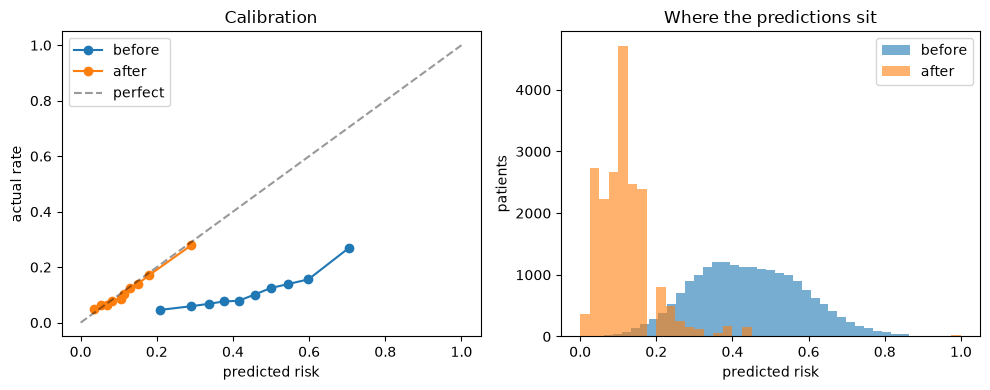

above 0.5 before: 34.9%
above 0.5 after:  0.2%


In [21]:
actual_before, expected_before = calibration_curve(y_test, pred_before, n_bins=10, strategy="quantile")
actual_after, expected_after = calibration_curve(y_test, pred_after, n_bins=10, strategy="quantile")

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(expected_before, actual_before, "o-", label="before")
plt.plot(expected_after, actual_after, "o-", label="after")
plt.plot([0, 1], [0, 1], "k--", alpha=0.4, label="perfect")
plt.xlabel("predicted risk")
plt.ylabel("actual rate")
plt.title("Calibration")
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(pred_before, bins=40, alpha=0.6, label="before")
plt.hist(pred_after, bins=40, alpha=0.6, label="after")
plt.xlabel("predicted risk")
plt.ylabel("patients")
plt.title("Where the predictions sit")
plt.legend()

plt.tight_layout()
plt.show()

print("above 0.5 before: %.1f%%" % ((pred_before >= 0.5).mean() * 100))
print("above 0.5 after:  %.1f%%" % ((pred_after >= 0.5).mean() * 100))

Brier more than halves and the mean prediction lands on the real rate, while AUC barely
moves.

It also shows the 0.5 threshold was never meaningful. After calibration almost nobody sits
above it, because almost nobody genuinely has a better-than-even chance of returning.

## 11. Why was a patient flagged?

SHAP gives each feature a signed contribution to each prediction. `TreeExplainer` is exact
for trees, and 2,000 rows is enough for a summary.

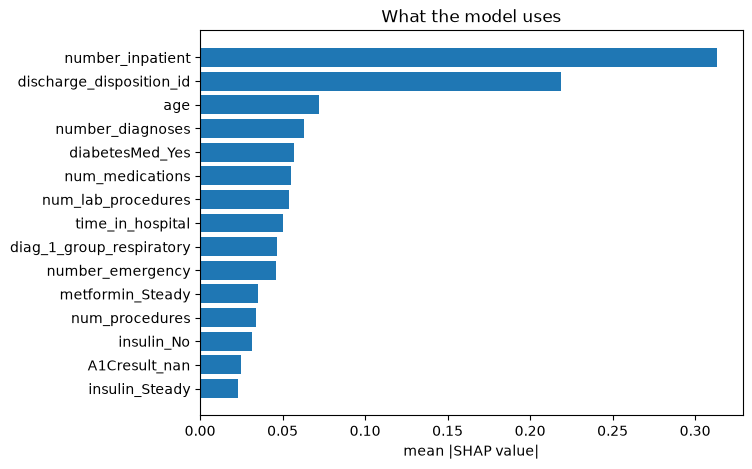

In [22]:
import shap

sample = X_test.sample(2000, random_state=42)
explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(sample)

importance = pd.Series(np.abs(shap_values).mean(axis=0), index=sample.columns)
top15 = importance.sort_values().tail(15)

plt.figure(figsize=(7, 5))
plt.barh(top15.index, top15.values)
plt.xlabel("mean |SHAP value|")
plt.title("What the model uses")
plt.show()

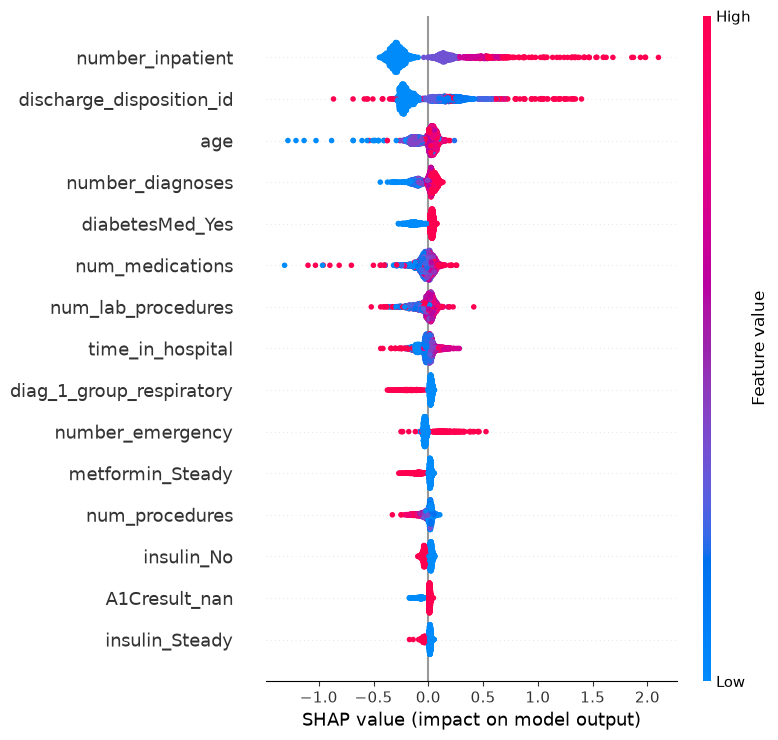

In [23]:
shap.summary_plot(shap_values, sample, max_display=15)

`insulin_Up` and `insulin_Down` are changes made during the stay, not dose levels. Patients
whose insulin was adjusted either way are readmitted at 13.0-13.9% against 10.0% for those
on none, so the signal is instability at discharge.

`A1Cresult_nan` is "no A1C was ordered", not missing data.

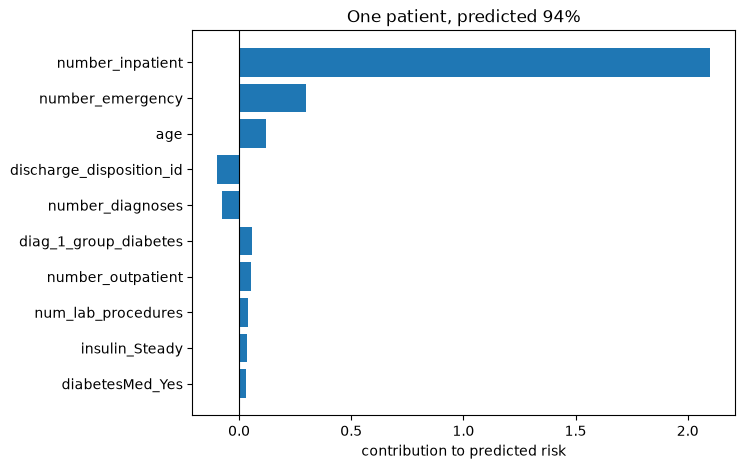

number_inpatient               12
number_emergency                3
age                            25
discharge_disposition_id        1
number_diagnoses                5
diag_1_group_diabetes        True
number_outpatient               2
num_lab_procedures             11
insulin_Steady              False
diabetesMed_Yes              True
Name: 97568, dtype: object


In [24]:
risk = xgb.predict_proba(sample)[:, 1]
riskiest = int(np.argmax(risk))

contributions = pd.Series(shap_values[riskiest], index=sample.columns)
top10 = contributions[contributions.abs().sort_values().tail(10).index]

plt.figure(figsize=(7, 5))
plt.barh(top10.index, top10.values)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("contribution to predicted risk")
plt.title("One patient, predicted %.0f%%" % (risk[riskiest] * 100))
plt.show()

print(sample.iloc[riskiest][top10.index[::-1]])

## 12. Fairness

Demographics come back from the raw data using the test index, since feature building
encoded them away. Groups under 50 rows are skipped as their AUC would be noise.

In [25]:
demographics = df.loc[X_test.index, ["race", "gender", "age"]]

def fairness_table(truth, scores, groups):
    rows = []
    for level in groups.dropna().unique():
        mask = (groups == level)
        if mask.sum() < 50 or truth[mask].nunique() < 2:
            continue
        rows.append({
            "group": level,
            "n": mask.sum(),
            "actual_rate": truth[mask].mean(),
            "flagged_at_0.5": (scores[mask.values] >= 0.5).mean(),
            "auc": roc_auc_score(truth[mask], scores[mask.values]),
        })
    return pd.DataFrame(rows).sort_values("n", ascending=False)

by_race = fairness_table(y_test, pred_xgb, demographics["race"])
by_gender = fairness_table(y_test, pred_xgb, demographics["gender"])
by_age = fairness_table(y_test, pred_xgb, demographics["age"]).sort_values("group")

print(by_race.round(3).to_string(index=False))
print()
print(by_gender.round(3).to_string(index=False))
print()
print(by_age.round(3).to_string(index=False))

          group     n  actual_rate  flagged_at_0.5   auc
      Caucasian 14886        0.115           0.362 0.667
AfricanAmerican  3707        0.107           0.360 0.658
       Hispanic   371        0.105           0.272 0.772
          Other   298        0.087           0.242 0.723
          Asian   122        0.082           0.230 0.721

 group     n  actual_rate  flagged_at_0.5   auc
Female 10645        0.112           0.367 0.677
  Male  9157        0.112           0.338 0.656

   group    n  actual_rate  flagged_at_0.5   auc
 [10-20)  138        0.065           0.036 0.556
 [20-30)  388        0.155           0.376 0.856
 [30-40)  729        0.106           0.259 0.694
 [40-50) 1909        0.106           0.252 0.664
 [50-60) 3469        0.103           0.259 0.706
 [60-70) 4266        0.109           0.316 0.646
 [70-80) 5040        0.116           0.424 0.654
 [80-90) 3287        0.119           0.467 0.638
[90-100)  547        0.128           0.470 0.565


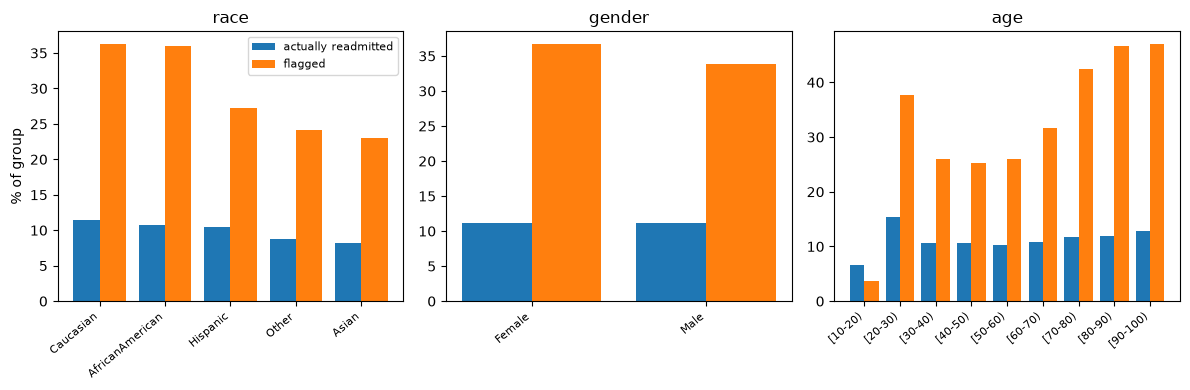

In [26]:
plt.figure(figsize=(12, 4))
for i, (table, name) in enumerate([(by_race, "race"), (by_gender, "gender"), (by_age, "age")], 1):
    plt.subplot(1, 3, i)
    positions = np.arange(len(table))
    plt.bar(positions - 0.2, table["actual_rate"] * 100, 0.4, label="actually readmitted")
    plt.bar(positions + 0.2, table["flagged_at_0.5"] * 100, 0.4, label="flagged")
    plt.xticks(positions, table["group"].astype(str), rotation=40, ha="right", fontsize=8)
    plt.title(name)
    if i == 1:
        plt.ylabel("% of group")
        plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

The 80-90 band is flagged at 48% while 11.9% of them actually return, and AUC drops to 0.54
for the over-90s. I expected race to be the problem and it is age.

Not fixed. A per-group threshold evens out recall, but recall was not the gap.

## Summary

In [27]:
print("stays:    %d" % len(df))
print("patients: %d" % df["patient_nbr"].nunique())
print("features: %d" % X.shape[1])
print()
print("logistic regression auc  %.4f" % roc_auc_score(y_test, pred_logreg))
print("xgboost auc              %.4f" % roc_auc_score(y_test, pred_xgb))
print("number_inpatient alone   %.4f" % auc_simple)
print("leakage if split by row  %+.4f" % (auc_random - auc_patient))
print("brier after calibration  %.4f" % brier_score_loss(y_test, pred_after))

stays:    99343
patients: 69990
features: 112

logistic regression auc  0.6506
xgboost auc              0.6673
number_inpatient alone   0.6022
leakage if split by row  +0.0066
brier after calibration  0.0953
